# Comparing models under consistent scoring: FZ0, Diebold-Mariano and the model confidence set in five stress windows

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 03 and 04 of this topic (the backtests that decide eligibility)
- **Reading time:** about 45 minutes

**Question:** Among the models that pass the eligibility gates, which one forecasts VaR and ES best in a stress window, and can that champion be told apart from the others?

## Objectives

By the end of this notebook you can:

- say why VaR and ES must be scored together, and write and compute the FZ0 loss with the engine's function;
- show with a scale experiment what it means for a scoring rule to be consistent, and read the result for three models;
- compare two models with the Diebold-Mariano test, say what its sign means, and find which models beat the champion on FZ0 and on the tick loss;
- recompute the model confidence set of the two windows that commit their returns, read the three others, and say why they cannot be recomputed;
- state the champion rule (eligibility by the traditional backtests, then ranking by FZ0) and apply it to the five stress windows.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2 arch==8.0.0 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib", "arch", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2
arch 8.0.0
pandas 3.0.6


## Data

Five windows of case C11 are read, one per market stress: `equity-2007-09` (the financial crisis), `equity-2020` (the pandemic crash), `rates-2022` (the hiking cycle), `fx-2008` (the euro against the dollar) and `mixed-2023` (the bank turmoil). Each holds, for 17 models and two tail levels, the VaR and ES paths, the mean FZ0 and tick loss, the eligibility verdict and a `comparison` block with the champion, the Diebold-Mariano rows against it and the model confidence set.

Only `rates-2022` and `fx-2008` commit the realised losses (their sources are `mirror-allowed`); the three others hold derived-only returns. The scores of those two windows are therefore recomputed here from the arrays, and the three others are read from the committed rows. The next cell loads the files and the helper that gathers one window's forecasts and scores.

In [2]:
# Load the five windows of case C11 and define the reader that gathers one window's forecasts for a tail level
ROOT = Path("../../..").resolve()
NAMES = ("equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
C11 = ROOT / "data" / "derived" / "C11"
docs = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in NAMES}
STATUS = {"included": "committed", "withheld-derived-only": "withheld"}


def forecasts_of(window, alpha):
    """Per model: VaR and ES in the return convention (ES None without one) and the eligibility verdict."""
    out = {}
    for model in docs[window]["outputs"]["models"]:
        level = [lv for lv in model["by_level"] if lv["alpha"] == alpha][0]
        es = None if level["es_status"] != "forecast" else -np.array(level["es"])
        out[model["model_id"]] = (-np.array(level["var"]), es, model["eligible"])
    return out


for w in NAMES:
    out = docs[w]["outputs"]
    status = STATUS[out["grid"]["realised_loss"]["status"]]
    print(f"{w:15s} {out['window']['n_forecast_days']:4d} days | realised losses {status:11s} | "
          f"eligible models {int(docs[w]['impact']['eligible_models']['value'])}")

equity-2007-09   504 days | realised losses withheld    | eligible models 0
equity-2020      104 days | realised losses withheld    | eligible models 4
rates-2022       249 days | realised losses committed   | eligible models 4
fx-2008          251 days | realised losses committed   | eligible models 10
mixed-2023        64 days | realised losses withheld    | eligible models 17


## Method

### Step 1: scoring VaR and ES together, the FZ0 loss

A scoring rule is **consistent** for a statistic if reporting the true statistic minimises the expected score, so a forecaster is rewarded for honesty. The VaR is elicitable: the tick (pinball) loss $(\alpha - \mathbb 1\{y < v\})(y - v)$ is consistent for it. The ES is not elicitable on its own (Gneiting, 2011), but the **pair** (VaR, ES) is (Fissler and Ziegel, 2016), so there are losses that reward a forecaster for the right VaR and the right ES at once. Patton, Ziegel and Chen (2019) pick the one whose loss differences are homogeneous of degree zero, free of tuning parameters, the FZ0 loss. In the return convention, with $y$ the realised return, $v < 0$ the VaR, $e \le v$ the ES:

$$L_{FZ0}(y, v, e; \alpha) = -\frac{1}{\alpha\,e}\,\mathbb 1\{y \le v\}\,(v - y) + \frac{v}{e} + \ln(-e) - 1$$

The loss can be negative and only **differences** between models are meaningful. The engine's `fz0_loss(y, v, e, alpha)` gives it day by day, `tick_loss` the pinball loss and `mean_scores` the means. The cell writes the loss by hand for one model to show its two parts, calls the engine on the same forecast, and then computes the mean FZ0 of every model with an ES in `fx-2008` at 2.5 percent for the figure.

ewma: mean FZ0 by hand -3.706963 | engine -3.706963
FZ0 on a day without exceedance: -3.9515 | on the 8 exceedance days: 3.7209


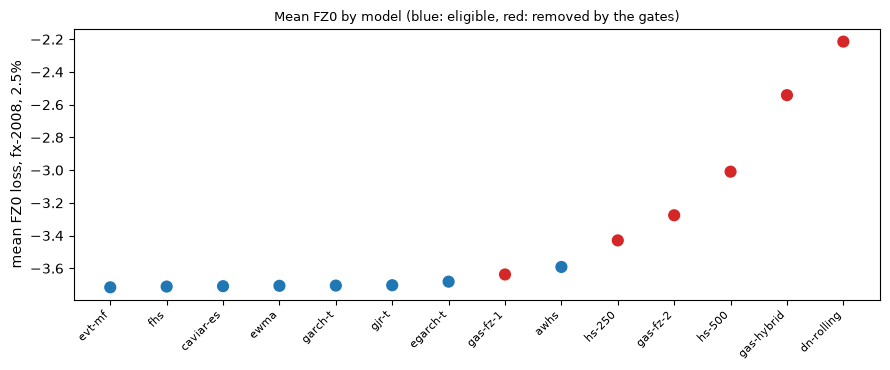

In [3]:
# FZ0 by hand for ewma at 2.5% against the engine, then the mean FZ0 of every model with an ES, drawn by
# eligibility
from riskvalidation.market.scoring import fz0_loss, mean_scores, tick_loss

returns = -np.array(docs["fx-2008"]["outputs"]["grid"]["realised_loss"]["loss"])
alpha = 0.025
book = forecasts_of("fx-2008", alpha)
v, e, _ = book["ewma"]
hit = returns <= v
by_hand = -(1.0 / (alpha * e)) * hit * (v - returns) + v / e + np.log(-e) - 1.0
print(f"ewma: mean FZ0 by hand {by_hand.mean():.6f} | engine {fz0_loss(returns, v, e, alpha).mean():.6f}")
print(f"FZ0 on a day without exceedance: {by_hand[~hit].mean():.4f} | "
      f"on the {int(hit.sum())} exceedance days: {by_hand[hit].mean():.4f}")

means = {m: mean_scores(returns, vm, em, alpha).fz0_mean for m, (vm, em, _) in book.items() if em is not None}
ranked = sorted(means, key=means.get)
colour = ["tab:blue" if book[m][2] else "tab:red" for m in ranked]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.scatter(range(len(ranked)), [means[m] for m in ranked], c=colour, s=60)
ax.set_xticks(range(len(ranked)), ranked, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("mean FZ0 loss, fx-2008, 2.5%")
ax.set_title("Mean FZ0 by model (blue: eligible, red: removed by the gates)", fontsize=9)
fig.tight_layout()
plt.show()

The FZ0 loss of `ewma` is -3.9515 on a day without an exceedance and +3.7209 on the 8 exceedance days: the exceedance term is what the score punishes, and the engine's mean (-3.706963) is the one written by hand. In the figure the seven blue dots at the left are the eligible models with the lowest mean FZ0, bunched within a few hundredths of each other around -3.7, so the score alone barely separates them. A red dot is better than a blue one: `gas-fz-1`, which the gates removed, scores below the eligible `awhs`. That is why ranking comes after eligibility and not instead of it. The figure shows the mean loss only; whether a difference of a few hundredths is more than luck is what the Diebold-Mariano test of step 3 decides.

### Step 2: what consistency means, shown by scaling a forecast

If the score is consistent, a forecast that is too small should score worse than a better one, and the **best scaling** of a model's forecast tells how far it is from its own optimum. The cell multiplies the VaR and the ES of three models in `fx-2008` at 2.5 percent by a factor $k$ from 0.6 to 1.8 and computes the mean FZ0 of each scaled forecast. The factor at which the curve is lowest is the one the realised returns prefer: near 1 means the forecast was already the best of its scaled family; far above 1 means it was too small for what happened.

ewma    k = 1: mean FZ0 -3.7070 | best factor 1.05: -3.7114
evt-mf  k = 1: mean FZ0 -3.7162 | best factor 1.00: -3.7162
hs-250  k = 1: mean FZ0 -3.4294 | best factor 1.40: -3.6350


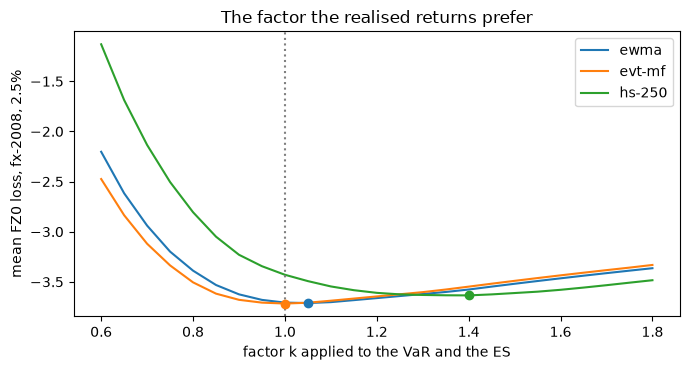

In [4]:
# Mean FZ0 of the VaR and ES of three models multiplied by a factor k, and the factor each model prefers
factors = np.linspace(0.6, 1.8, 25)
curves = {}
for model_id in ("ewma", "evt-mf", "hs-250"):
    v, e, _ = book[model_id]
    curves[model_id] = np.array([fz0_loss(returns, k * v, k * e, 0.025).mean() for k in factors])
    best = int(np.argmin(curves[model_id]))
    print(f"{model_id:7s} k = 1: mean FZ0 {fz0_loss(returns, v, e, 0.025).mean():.4f} | "
          f"best factor {factors[best]:.2f}: {curves[model_id][best]:.4f}")

fig, ax = plt.subplots(figsize=(7, 3.8))
for model_id, curve in curves.items():
    ax.plot(factors, curve, label=model_id)
    ax.scatter(factors[int(np.argmin(curve))], curve.min(), zorder=3)
ax.axvline(1.0, color="grey", linestyle=":")
ax.set_xlabel("factor k applied to the VaR and the ES")
ax.set_ylabel("mean FZ0 loss, fx-2008, 2.5%")
ax.set_title("The factor the realised returns prefer")
ax.legend()
fig.tight_layout()
plt.show()

Each curve is the mean FZ0 of one model when its VaR and ES are multiplied by $k$, and the dot marks the factor the realised returns preferred. For `evt-mf` the lowest point is at $k = 1.00$ (-3.7162): its forecast was already the best of its scaled family. For `ewma` it is at 1.05 (-3.7114 against -3.7070 unscaled). For `hs-250` it is at 1.40 (-3.6350 against -3.4294): in the 2008 crisis the historical forecast would have needed numbers 40 percent larger to score best in its family, and the score says so with a gap of about 0.21. The experiment shows that FZ0 rewards the right size and not only the right ranking of days; it does not say that scaling a forecast by 1.40 would have been a good model, only where the loss is lowest on one window.

### Step 3: Diebold-Mariano against the champion

To say that one model is better than another, and not just lucky on this window, Diebold and Mariano (1995) test whether the mean of the loss differential $d_t = L_t^{A} - L_t^{B}$ is zero:

$$DM = \frac{\bar d}{\sqrt{\widehat{\mathrm{LRV}}/T}} \xrightarrow{d} N(0,1), \qquad \widehat{\mathrm{LRV}} = \hat\gamma_0 + 2\sum_{j=1}^{h}\left(1 - \tfrac{j}{h+1}\right)\hat\gamma_j$$

with $\hat\gamma_j$ the sample autocovariances of $d_t$ and $h$ the Bartlett lags; for one-step forecasts $h = 0$. A **negative** $\bar d$ means model A has the lower loss, so it is better. The engine's `diebold_mariano(loss_a, loss_b, lags)` returns the mean difference, the statistic and the two-sided normal p-value. The cell picks the champion by the rule of step 5 (the lowest mean FZ0 among the eligible models that have an ES), compares every other model with it on FZ0 in `fx-2008` and `rates-2022` at both levels, and draws the statistics for `fx-2008` at 2.5 percent.

fx-2008     alpha 0.010 | champion caviar-es | significantly better 0 | worse 5 of 13
fx-2008     alpha 0.025 | champion evt-mf | significantly better 0 | worse 4 of 13
rates-2022  alpha 0.010 | champion ewma | significantly better 0 | worse 4 of 13
rates-2022  alpha 0.025 | champion ewma | significantly better 0 | worse 2 of 13


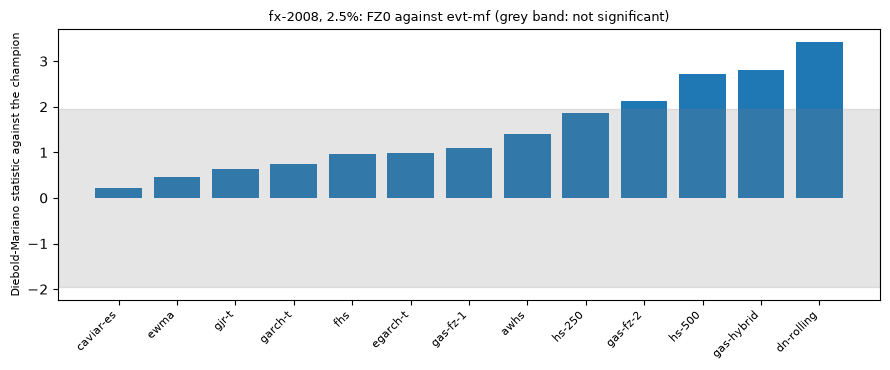

In [5]:
# Champion by the rule of step 5, then Diebold-Mariano of every other model against it on FZ0, at both levels
from riskvalidation.market.scoring import diebold_mariano

dm = {}
for window in ("fx-2008", "rates-2022"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        book = forecasts_of(window, alpha)
        fz = {m: fz0_loss(y, vm, em, alpha) for m, (vm, em, _) in book.items() if em is not None}
        champion = min((m for m in fz if book[m][2]), key=lambda m: fz[m].mean())
        results = {m: diebold_mariano(fz[m], fz[champion], 0) for m in fz if m != champion}
        dm[(window, alpha)] = (champion, results)
        better = sum(r.p_value < 0.05 and r.mean_diff < 0 for r in results.values())
        worse = sum(r.p_value < 0.05 and r.mean_diff > 0 for r in results.values())
        print(f"{window:11s} alpha {alpha:5.3f} | champion {champion} | "
              f"significantly better {better} | worse {worse} of {len(results)}")

champion, results = dm[("fx-2008", 0.025)]
names = sorted(results, key=lambda m: results[m].statistic)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(names)), [results[m].statistic for m in names], color="tab:blue")
ax.axhspan(-1.96, 1.96, color="grey", alpha=0.2)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Diebold-Mariano statistic against the champion", fontsize=8)
ax.set_title(f"fx-2008, 2.5%: FZ0 against {champion} (grey band: not significant)", fontsize=9)
fig.tight_layout()
plt.show()

In `fx-2008` at 2.5 percent every model has a positive statistic, that is, a higher loss than the champion `evt-mf`, but only four of the 13 cross the grey band of 1.96: `gas-fz-2`, `hs-500`, `gas-hybrid` and `dn-rolling`. The EWMA, the GARCH family, `fhs` and `caviar-es` cannot be told apart from the champion, and `hs-250` stays just inside the band. The printed counts say the same for all four cases: no model is significantly better than the champion, and between 2 and 5 of the 13 are significantly worse. The figure shows that a champion chosen by the lowest mean is a ranking, not a proof of superiority: with 251 days most of the ladder is statistically level with it.

The FZ0 loss scores the VaR and the ES together; the tick loss scores the VaR alone, so a ranking by the tick loss can differ from the one by FZ0, especially for a rung that has no ES. The next cell takes the FZ0 champion of `rates-2022` at 1 percent and asks which models beat it on the tick loss with `tick_loss` and `diebold_mariano`.

In [6]:
# The tick loss (VaR only) of every model in rates-2022 at 1%, compared with the FZ0 champion by Diebold-Mariano
y = -np.array(docs["rates-2022"]["outputs"]["grid"]["realised_loss"]["loss"])
book = forecasts_of("rates-2022", 0.01)
champion, fz_results = dm[("rates-2022", 0.01)]
tick = {m: tick_loss(y, vm, 0.01) for m, (vm, em, _) in book.items()}
winners = {}
for model_id in tick:
    if model_id != champion:
        result = diebold_mariano(tick[model_id], tick[champion], 0)
        if result.p_value < 0.05 and result.mean_diff < 0:
            winners[model_id] = (result.p_value, book[model_id][1] is not None, book[model_id][2])
print(f"FZ0 champion: {champion}")
print(f"models significantly better on the tick loss: {len(winners)}")
for model_id, (p_value, has_es, eligible) in winners.items():
    print(f"  {model_id}: p {p_value:.4f} | has an ES: {'yes' if has_es else 'no'} | "
          f"eligible: {'yes' if eligible else 'no'}")

FZ0 champion: ewma
models significantly better on the tick loss: 1
  cf-rolling: p 0.0438 | has an ES: no | eligible: no


### Step 4: the model confidence set

Diebold-Mariano compares two models. The model confidence set of Hansen, Lunde and Nason (2011) answers the question a validator asks about a whole ladder: which models are **not distinguishable from the best**? It starts with all models, tests the hypothesis that they have equal expected loss, and while it is rejected eliminates the worst model, using a bootstrap for the null distribution; the models that survive form the set, at confidence $1-\alpha_{MCS}$. Contraste uses the range statistic ($T_R$), 90 percent confidence, a stationary bootstrap of 1,000 draws with blocks of 10 days and the FZ0 loss. A model is in the set when its MCS p-value is at least 0.10. The engine computes it with `arch.bootstrap.MCS` (the optional `market` extra, installed in this environment with `pandas`), seeded: the same losses and the same seed give the same p-values. Two windows commit their realised returns, `rates-2022` and `fx-2008`, so the cell recomputes their sets at both levels from the forecasts with the settings the artifact records; the three other windows hold derived-only returns, so their sets are read, not recomputed. The figure draws the MCS p-values of `fx-2008` at 1 percent.

rates-2022  alpha 0.010 | set 14 of 14
rates-2022  alpha 0.025 | set 12 of 14
fx-2008     alpha 0.010 | set 13 of 14
fx-2008     alpha 0.025 | set 13 of 14
equity-2007-09  set at 1% (read): 12 of 14
equity-2020     set at 1% (read): 14 of 14
mixed-2023      set at 1% (read): 2 of 14


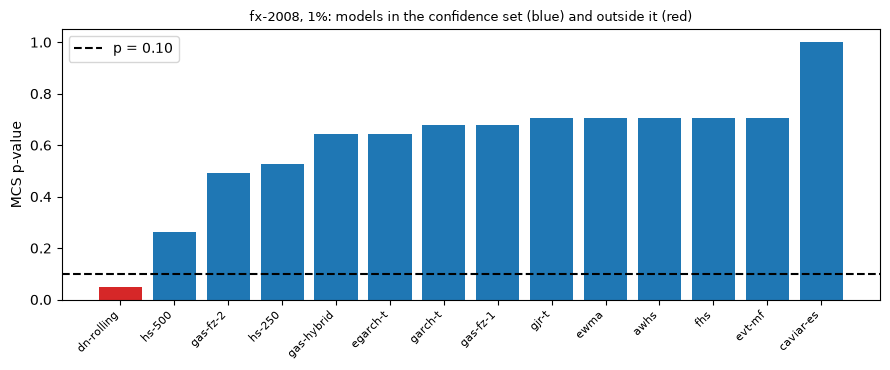

In [7]:
# Recompute the model confidence set of the two windows that commit returns, read the three others, draw
# fx-2008 at 1%
from riskvalidation.market.scoring import model_confidence_set

sets = {}
for window in ("rates-2022", "fx-2008"):
    y = -np.array(docs[window]["outputs"]["grid"]["realised_loss"]["loss"])
    for alpha in (0.01, 0.025):
        setting = [m for m in docs[window]["outputs"]["comparison"]["mcs"] if m["alpha"] == alpha][0]
        ids = [m["model_id"] for m in setting["members"]]
        book = forecasts_of(window, alpha)
        losses = np.column_stack([fz0_loss(y, book[i][0], book[i][1], alpha) for i in ids])
        args = (setting["confidence"], setting["statistic"], setting["n_bootstrap"], setting["block_length"], 42)
        sets[(window, alpha)] = (ids, model_confidence_set(losses, *args))
        print(f"{window:11s} alpha {alpha:5.3f} | set {len(sets[(window, alpha)][1].members)} of {len(ids)}")
for window in ("equity-2007-09", "equity-2020", "mixed-2023"):
    mcs = [m for m in docs[window]["outputs"]["comparison"]["mcs"] if m["alpha"] == 0.01][0]
    print(f"{window:15s} set at 1% (read): {mcs['n_in_set']} of {len(mcs['members'])}")

ids, fresh = sets[("fx-2008", 0.01)]
order = np.argsort(fresh.p_values)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(ids)), fresh.p_values[order], color=["tab:blue" if i in fresh.members else "tab:red" for i in order])
ax.axhline(0.10, color="black", linestyle="--", label="p = 0.10")
ax.set_xticks(range(len(ids)), [ids[i] for i in order], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("MCS p-value")
ax.set_title("fx-2008, 1%: models in the confidence set (blue) and outside it (red)", fontsize=9)
ax.legend()
fig.tight_layout()
plt.show()

Each bar is the MCS p-value of a model in `fx-2008` at 1 percent, and a model is in the set when its bar clears the dashed line at 0.10. Only `dn-rolling` (p about 0.05) is outside the set, `hs-500` is the next weakest at about 0.26, and `caviar-es`, the champion, has p of 1 by construction. The recomputed sets hold 13 of 14 models in `fx-2008` at both levels and 14 of 14 and 12 of 14 in `rates-2022`; the committed sets of the windows whose returns are withheld hold 12 of 14 in `equity-2007-09`, 14 of 14 in `equity-2020` and 2 of 14 in `mixed-2023`. A window with few days or few losses separates models poorly; `mixed-2023` separates them because no model has an exceedance in its 64 days, the indicator term of FZ0 vanishes and the score is decided by how small the forecast ES is. The figure shows who cannot be excluded, not who is best.

### Step 5: the champion rule

The ladder separates two questions. **Eligibility** asks whether a model is acceptable: it must not be red on Kupiec, on conditional coverage or on the Acerbi-Szekely test at either level (notebooks 03 and 04). **Ranking** asks which acceptable model forecasts best: the lowest mean FZ0, among the eligible models that have an ES on every day. This is the comparative-backtest frame of Nolde and Ziegel (2017): a validator wants to know whether a challenger beats the champion, not only whether the champion is rejected. A window can have no champion: if no eligible model has an ES on every day there is no FZ0 score to rank, and the document says so instead of choosing one. The cell reads the committed champions and the number of eligible models in the five windows, and the mean FZ0 of the champion.

window           eligible  champion 1%        champion 2.5%     
equity-2007-09          0  -                  -                 
equity-2020             4  fhs -1.986         evt-mf -2.364     
rates-2022              4  ewma -3.811        ewma -4.002       
fx-2008                10  caviar-es -3.557   evt-mf -3.716     
mixed-2023             17  gjr-t -4.439       gjr-t -4.623      


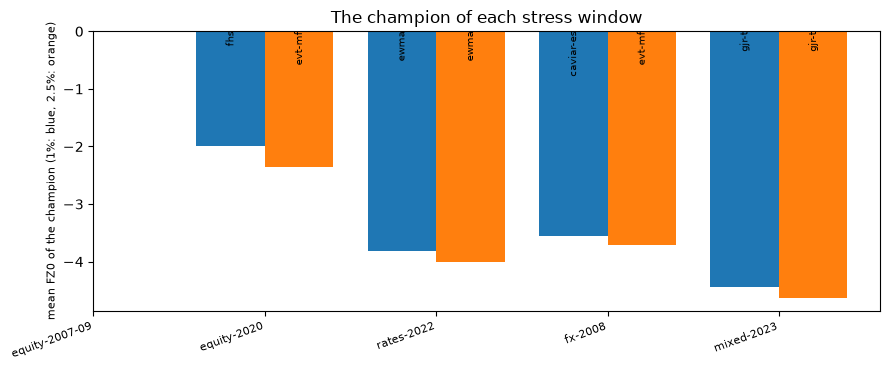

In [8]:
# Eligible models, champions and the champion's mean FZ0 in the five windows, as committed, drawn at both levels
fig, ax = plt.subplots(figsize=(9, 3.8))
print(f"{'window':15s} {'eligible':>9s}  {'champion 1%':18s} {'champion 2.5%':18s}")
for position, window in enumerate(NAMES):
    outputs = docs[window]["outputs"]
    champions = {c["alpha"]: c["model_id"] for c in outputs["comparison"]["champions"]}
    level_of = {(m["model_id"], lv["alpha"]): lv for m in outputs["models"] for lv in m["by_level"]}
    eligible = int(docs[window]["impact"]["eligible_models"]["value"])
    scores = {a: level_of[(champions[a], a)]["fz0_mean"] if champions[a] else None for a in (0.01, 0.025)}
    cells = [f"{champions[a]} {scores[a]:.3f}" if scores[a] is not None else "-" for a in scores]
    print(f"{window:15s} {eligible:9d}  {cells[0]:18s} {cells[1]:18s}")
    for shift, alpha in ((-0.2, 0.01), (0.2, 0.025)):
        if scores[alpha] is not None:
            ax.bar(position + shift, scores[alpha], width=0.4, color="tab:blue" if alpha == 0.01 else "tab:orange")
            ax.annotate(champions[alpha], (position + shift, 0), ha="center", va="top", fontsize=7, rotation=90)
ax.set_xticks(range(len(NAMES)), NAMES, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("mean FZ0 of the champion (1%: blue, 2.5%: orange)", fontsize=8)
ax.set_title("The champion of each stress window")
fig.tight_layout()
plt.show()

Each pair of bars is the mean FZ0 of the champion of a window at 1 percent (blue) and 2.5 percent (orange), labelled with its name; `equity-2007-09` has no bars because no model is eligible there and the document says so instead of choosing one. The champion changes with the window: `fhs` and `evt-mf` in `equity-2020`, `ewma` in `rates-2022`, `caviar-es` and `evt-mf` in `fx-2008` and `gjr-t` in `mixed-2023`, and in no window is it a simple historical simulation. FZ0 levels are not comparable across windows, since the scale of the returns differs, so the figure is read bar by bar and never as a ranking of windows.

## Results

**Answer:** In `fx-2008` the champion is `caviar-es` at 1 percent (mean FZ0 -3.557) and `evt-mf` at the 0.025 level (-3.716), but it cannot be told apart from most of the ladder: no model is significantly better than it, only some of the 13 others are significantly worse (5 at the 0.01 level, 4 at 0.025), and 13 of 14 models sit in the confidence set. The champion also changes with the window (`fhs`, `ewma`, `caviar-es`, `gjr-t`) and is never a simple historical simulation.

- **FZ0, by hand and by engine.** For `ewma` at 2.5 percent in `fx-2008` the mean FZ0 is -3.706963 by hand and by the engine. The loss is -3.9515 on average on a day without an exceedance and +3.7209 on the 8 exceedance days: the exceedance term is what the score punishes.
- **Consistency, shown by scale.** Multiplying the VaR and ES of `evt-mf` by a factor $k$ gives its lowest mean FZ0 at $k = 1.00$ (-3.7162); for `ewma` at 1.05 (-3.7114 against -3.7070 unscaled); for `hs-250` at 1.40 (-3.6350 against -3.4294 unscaled).
- **Diebold-Mariano.** The rule gives the champions `caviar-es` and `evt-mf` in `fx-2008` and `ewma` at both levels in `rates-2022`. No model is significantly better than the champion on FZ0 in any of the four cases. On the tick loss, which sees only the VaR, one model beats the `rates-2022` champion at 1 percent: `cf-rolling` (p 0.0438), which has no ES and is not eligible.
- **The confidence set.** The recomputed sets hold 14 of 14 models in `rates-2022` at 1 percent, 12 of 14 at 2.5 percent, and 13 of 14 in `fx-2008` at both levels. The committed sets of the three windows with withheld returns hold 12 of 14 (`equity-2007-09`), 14 of 14 (`equity-2020`) and 2 of 14 (`mixed-2023`).
- **The champion rule on five windows.** `equity-2007-09` has no champion because no model is eligible. `equity-2020` has 4 eligible models and champions `fhs` (FZ0 -1.986) and `evt-mf` (-2.364). `rates-2022` has 4 eligible and `ewma` at both levels (-3.811, -4.002). `fx-2008` has 10 eligible. `mixed-2023` has 17 eligible and `gjr-t` at both levels (-4.439, -4.623).

What this notebook does not show: any test of a desk-level model (notebook 06), or the dynamic semiparametric models in detail (notebook 07).

## Summary

- VaR and ES are scored together because the pair is jointly elicitable; the FZ0 loss is the parameter-free member of that class. Its level means nothing, its differences between models do.
- A consistent score rewards the right forecast: scaling a forecast shows how far each model is from its own best scale, and a model that was too small in a crisis prefers a larger factor.
- Diebold-Mariano turns a difference in mean loss into a test; a negative sign means the first model is better. With the champion fixed, most of the ladder is statistically level with it on FZ0, and the tick loss can rank a VaR-only rung above it.
- The model confidence set answers a different question, which models cannot be told apart from the best. It is seeded, so the two windows that commit their returns are recomputed here; the three others are read, since their returns are withheld.
- The champion is chosen in two steps: eligibility by the traditional backtests, then the lowest FZ0 among the eligible models with an ES on every day. A window can have no champion, and the document says so.

**What to try next.** Pick another window and level in step 3 and find a model that is significantly worse than the champion on FZ0 and indistinguishable on tick loss; then continue with notebook 06, which moves from models to desks.

## References

- Gneiting, T. (2011), Making and evaluating point forecasts, Journal of the American Statistical Association 106(494). https://doi.org/10.1198/jasa.2011.r10138
- Fissler, T. and Ziegel, J. F. (2016), Higher order elicitability and Osband's principle, Annals of Statistics 44(4). https://doi.org/10.1214/16-AOS1439
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Diebold, F. X. and Mariano, R. S. (1995), Comparing predictive accuracy, Journal of Business and Economic Statistics 13(3). https://doi.org/10.1080/07350015.1995.10524599
- Hansen, P. R., Lunde, A. and Nason, J. M. (2011), The model confidence set, Econometrica 79(2). https://doi.org/10.3982/ECTA5771
- Nolde, N. and Ziegel, J. F. (2017), Elicitability and backtesting: perspectives for banking regulation, Annals of Applied Statistics 11(4). https://doi.org/10.1214/17-AOAS1041